# Singularidad en Matrices Bohemias Hessenberg Superiores: Anatomía y Tasa Geométrica

Kevin Josué Martínez Herrera, Escuela de Física, Universidad de Costa Rica.

Este cuaderno recorre los cálculos del proyecto: con qué probabilidad una matriz Bohemia Hessenberg superior aleatoria es singular, y por qué. Una matriz $H$ de $n\times n$ es Hessenberg superior si $h_{ij}=0$ para $i>j+1$. Es Bohemia (BOunded HEight Matrix of Integers) cuando sus entradas libres se toman de un conjunto fijo y pequeño, aquí $\{0,\dots,m-1\}$, de forma uniforme e independiente. Se comparan dos modelos, que difieren solo en la subdiagonal $s_i=h_{i+1,i}$:

* **Modelo normalizado**: $s_i=1$ (convención de Corless-Thornton).
* **Modelo libre**: $s_i\sim\mathrm{Unif}\{0,\dots,m-1\}$, por lo que puede anularse.

El orden sigue el del póster: la recurrencia del determinante, los resultados estructurales (corango y singularidad estructural), la enumeración exacta, el decaimiento geométrico $P(\text{singular})=\Theta(\gamma(m)^n)$, su descomposición con el exponente de Lyapunov, el modelo libre, el número de condición y, al final, la densidad de valores propios usada para la Figura 1 del póster.

Las funciones están en `bohemian/`. El tamaño de las muestras se controla con `FULL`: con `FULL = False` el cuaderno completo corre en unos 15 minutos en una laptop; `FULL = True` usa los tamaños del póster (principalmente las $10^8$ muestras de la densidad de valores propios).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))  # el paquete bohemian/ está en la carpeta superior

from bohemian.bohemian_analysis import (bareiss_det, exact_rank, exact_singular_probability,
                                        hessenberg_minors, make_hessenberg, why_singular)
from bohemian.bohemian_eigenvalues import bohemian_density, render
from bohemian.gamma_estimation import estimate_gamma, lyapunov, psing_rb_contribs
from bohemian.paper_experiments import condition_numbers, psing_free, psing_normalized

FULL = False  # True: tamaños de muestra del póster (más lento)
COL = {2: "#c1440e", 3: "#0f6e56", 5: "#2b5c8a", 10: "#7a4fb0", 20: "#b08900"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()

## 1. La recurrencia del determinante

Sea $d_k=\det H[1{:}k,1{:}k]$ el $k$-ésimo menor principal, con $d_0=1$. Al expandir por la última columna se obtiene la recurrencia continuante

$$d_k=\sum_{j=1}^{k}(-1)^{k-j}\,h_{j,k}\left(\prod_{i=j}^{k-1}s_i\right)d_{j-1},$$

que en el modelo normalizado se reduce a $d_k=\sum_{j=1}^{k}(-1)^{k-j}h_{j,k}\,d_{j-1}$. $H$ es singular si y solo si $d_n=0$. Cada columna nueva inyecta una combinación lineal nueva de todos los menores anteriores, y la singularidad es el evento de que esta sucesión aleatoria caiga exactamente en 0 en el paso $n$.

La recurrencia se evalúa en aritmética entera exacta, por lo que no hay redondeo (un determinante en punto flotante ya no es confiable alrededor de $n\approx 10$), y cuesta $O(n^2)$ en lugar del $O(n^3)$ de una factorización LU. A continuación, una matriz de cada modelo y una verificación de la recurrencia contra la eliminación entera de Bareiss.

In [2]:
rng = np.random.default_rng(1)
Hn = make_hessenberg(5, 4, normalized=True, rng=rng)
Hf = make_hessenberg(5, 4, normalized=False, rng=rng)
print("Modelo normalizado, n=5, m=4\n", Hn, "\nmenores d_0..d_5:", hessenberg_minors(Hn))
print("\nModelo libre, n=5, m=4\n", Hf, "\nmenores d_0..d_5:", hessenberg_minors(Hf))

# Verificación: recurrencia vs Bareiss en matrices aleatorias de ambos modelos
rng = np.random.default_rng(2)
checked, mismatches = 0, 0
for n in range(2, 11):
    for m in (2, 3, 5, 10):
        for normalized in (True, False):
            for _ in range(250):
                H = make_hessenberg(n, m, normalized, rng)
                mismatches += hessenberg_minors(H)[-1] != bareiss_det(H)
                checked += 1
print(f"\nrecurrencia vs Bareiss: {mismatches} diferencias en {checked:,} matrices")

Modelo normalizado, n=5, m=4
 [[1 2 3 3 0]
 [1 0 3 3 0]
 [0 1 1 3 1]
 [0 0 1 1 3]
 [0 0 0 1 1]] 
menores d_0..d_5: [1, 1, -2, -2, 4, 8]

Modelo libre, n=5, m=4
 [[1 2 2 0 0]
 [0 3 3 3 2]
 [0 1 3 1 1]
 [0 0 3 3 0]
 [0 0 0 0 1]] 
menores d_0..d_5: [1, 1, 3, 6, 18, 18]



recurrencia vs Bareiss: 0 diferencias en 18,000 matrices


## 2. Teoría estructural del modelo normalizado

La pregunta "¿por qué una matriz singular es singular?" se divide en causas estructurales (una fila o columna nula, dos filas o columnas iguales o proporcionales) y dependencia aritmética genuina. Para el modelo normalizado, dos argumentos cortos lo resuelven.

**Teorema 1 (corango a lo sumo uno).** Al eliminar la primera fila y la última columna queda un bloque de $(n-1)\times(n-1)$ en las filas $2,\dots,n$ y columnas $1,\dots,n-1$. Su diagonal es la subdiagonal de $H$, toda de unos, y todo lo que está debajo se anula por la forma Hessenberg, así que es triangular superior con diagonal unitaria y determinante 1. Por lo tanto $\operatorname{rank}(H)\geq n-1$, y una $H$ singular tiene un núcleo de dimensión exactamente 1.

**Teorema 2 (la singularidad estructural es exponencialmente rara).** Las filas $2,\dots,n$ tienen su 1 forzado en columnas distintas y son cero antes de él, por lo que ninguna pareja de ellas es igual, proporcional o nula. Un evento estructural, entonces, involucra a la fila 1: se anula, o es $c$ veces alguna fila $j\geq2$. La fila $j$ es cero hasta la columna $j-2$, tiene el 1 forzado en la columna $j-1$ y entradas libres después, así que $\text{fila}_1=c\,\text{fila}_j$ fija las $n$ entradas de la fila 1. Lo mismo ocurre con las columnas, donde solo la columna $n$ no tiene un 1 de la subdiagonal: se anula o es múltiplo de alguna columna $k\leq n-1$. Cada canal fija $n$ entradas independientes, así que tiene probabilidad a lo sumo $m^{-n}$, y con $n-1$ parejas y $m-1$ multiplicadores posibles de cada lado
$$P(\text{estructural})\leq\bigl(2(n-1)(m-1)+2\bigr)\,m^{-n}=O(n\,m^{1-n}).$$
El póster lo enuncia como $O(m^{-n})$, contando solo la fila 2 y la columna $n-1$ como parejas. La fila 1 también puede coincidir con una fila posterior cuando sus primeras entradas se anulan, lo que agrega el factor $n$. La conclusión no cambia, ya que la cota sigue siendo exponencialmente pequeña frente a la probabilidad total.

Ambos se verifican numéricamente: el rango exacto sobre $\mathbb{Q}$ de matrices singulares muestreadas, y la clasificación de por qué cada una es singular.

In [3]:
from collections import Counter

rng = np.random.default_rng(3)
print(f"{'n':>2} {'m':>3} {'singular':>9} {'corango=1':>9} {'P(sing)':>8} {'estruct.':>8}"
      f" {'P(struct)':>10} {'cota':>8}  razones")
for n, m in [(4, 2), (6, 2), (8, 2), (10, 2), (4, 3), (6, 3), (8, 3), (6, 5)]:
    tries, singular, reasons, corank_one = 0, 0, Counter(), 0
    while singular < 400:
        H = make_hessenberg(n, m, normalized=True, rng=rng)
        tries += 1
        if hessenberg_minors(H)[-1] == 0:
            singular += 1
            corank_one += exact_rank(H) == n - 1
            reasons[why_singular(H)] += 1
    frac = 1 - reasons["genuine"] / singular  # fracción de matrices singulares con causa estructural
    p = singular / tries
    print(f"{n:>2} {m:>3} {singular:>9} {corank_one:>9} {p:>8.4f} {frac:>8.3f}"
          f" {frac * p:>10.2e} {(2 * (n - 1) * (m - 1) + 2) * m**-n:>8.1e}  {dict(sorted(reasons.items()))}")

 n   m  singular corango=1  P(sing) estruct.  P(struct)     cota  razones
 4   2       400       400   0.4188    0.863   3.61e-01  5.0e-01  {'equal_col': 84, 'equal_row': 140, 'genuine': 55, 'zero_rowcol': 121}
 6   2       400       400   0.3518    0.458   1.61e-01  1.9e-01  {'equal_col': 59, 'equal_row': 90, 'genuine': 217, 'zero_rowcol': 34}


 8   2       400       400   0.2869    0.245   7.03e-02  6.2e-02  {'equal_col': 41, 'equal_row': 43, 'genuine': 302, 'zero_rowcol': 14}


10   2       400       400   0.2380    0.075   1.78e-02  2.0e-02  {'equal_col': 11, 'equal_row': 16, 'genuine': 370, 'zero_rowcol': 3}
 4   3       400       400   0.1894    0.682   1.29e-01  1.7e-01  {'equal_col': 85, 'equal_row': 80, 'genuine': 127, 'prop_col': 23, 'prop_row': 23, 'zero_rowcol': 62}


 6   3       400       400   0.1118    0.172   1.93e-02  3.0e-02  {'equal_col': 21, 'equal_row': 28, 'genuine': 331, 'prop_col': 7, 'prop_row': 7, 'zero_rowcol': 6}


 8   3       400       400   0.0671    0.032   2.18e-03  4.6e-03  {'equal_col': 6, 'equal_row': 3, 'genuine': 387, 'prop_col': 2, 'prop_row': 1, 'zero_rowcol': 1}


 6   5       400       400   0.0178    0.052   9.33e-04  2.7e-03  {'equal_col': 5, 'equal_row': 5, 'genuine': 379, 'prop_col': 2, 'prop_row': 6, 'zero_rowcol': 3}


Toda matriz singular muestreada tiene corango exactamente 1, como obliga el Teorema 1. Las razones estructurales que aparecen son los canales del Teorema 2: fila 1 o columna $n$ nulas (`zero_rowcol`), fila 1 igual o proporcional a una fila posterior (`equal_row`, `prop_row`), y columna $n$ igual o proporcional a una columna anterior (`equal_col`, `prop_col`). Para $n$ pequeño son una parte grande de las matrices singulares, pero su probabilidad `P(struct)` se mantiene por debajo de la cota del Teorema 2 (`cota`) dentro del error de muestreo (cada fila usa 400 matrices singulares; para $n=8$, $m=2$ una corrida con $6	imes10^4$ matrices da $0.0607\pm0.0010$ contra $0.0625$), y la cota decae como $n\,m^{-n}$, mientras que la probabilidad total de singularidad decae solo como $\gamma(m)^n$ con $\gamma(m)\gg m^{-1}$ (Sección 4). Así, la fracción estructural (`estruct.`) tiende a 0 con $n$, como muestran las filas de $m=2$ y $m=3$: condicionada a ser singular, una $H$ normalizada es casi seguramente singular por una razón genuina (Corolario 1). Esto es lo opuesto al caso denso de alfabeto fijo, donde la singularidad está dominada a primer orden por colisiones estructurales (Tikhomirov).

## 3. Enumeración exacta y la cota $1/m$

**Teorema 3.** En el modelo normalizado $P(H\text{ singular})\leq 1/m$ para todo $n,m$. El coeficiente de $h_{1,n}$ en $d_n$ es $(-1)^{n-1}d_0=\pm1$, por lo que $d_n=\pm h_{1,n}+R$ con $R$ independiente de $h_{1,n}$. Como $h_{1,n}$ toma cada uno de sus $m$ valores con probabilidad $1/m$, $P(d_n=0)=\tfrac1m P(\mp R\in\{0,\dots,m-1\})\leq 1/m$.

Para $(n,m)$ pequeños se enumera la familia completa ($m^{n(n+1)/2}$ matrices) y la probabilidad se obtiene como un racional exacto. Esta es la referencia exacta para las estimaciones por muestreo de más adelante. La cota se alcanza en $n=m=2$: $d_2=h_{11}h_{22}-h_{12}$, y sobre $\{0,1\}$ el producto $h_{11}h_{22}$ siempre cae dentro del alfabeto, así que exactamente uno de los dos valores de $h_{12}$ lo cancela.

In [4]:
print(f"{'n':>2} {'m':>2} {'matrices':>9} {'P(det H = 0)':>14} {'decimal':>8} {'1/m':>6}")
EXACT = {}
for n, m in [(2, 2), (2, 3), (2, 5), (3, 2), (3, 3), (4, 2), (4, 3), (5, 2), (6, 2)]:
    p = exact_singular_probability(n, m, normalized=True)
    EXACT[(n, m)] = p
    print(f"{n:>2} {m:>2} {m ** (n * (n + 1) // 2):>9,} {str(p):>14} {float(p):>8.4f} {1 / m:>6.3f}")

 n  m  matrices   P(det H = 0)  decimal    1/m
 2  2         8            1/2   0.5000  0.500
 2  3        27           8/27   0.2963  0.333
 2  5       125         17/125   0.1360  0.200
 3  2        64          15/32   0.4688  0.500
 3  3       729          19/81   0.2346  0.333
 4  2     1,024         55/128   0.4297  0.500
 4  3    59,049    10772/59049   0.1824  0.333
 5  2    32,768      1599/4096   0.3904  0.500
 6  2 2,097,152  185183/524288   0.3532  0.500


## 4. Decaimiento geométrico

La probabilidad de singularidad del modelo normalizado se estima por Monte Carlo con la recurrencia exacta (`int64` por lotes, que es exacto en estos rangos; el código verifica la cota de Hadamard). En escala semilogarítmica los puntos se alinean, es decir $P(\det H=0)=\Theta(\gamma(m)^n)$. Las filas $n\leq 6$, $m=2$ se pueden comparar contra los valores exactos de arriba. Para $m=20$ la probabilidad en $n=8$ es $\sim10^{-6}$, demasiado rara para contar directamente, así que esa columna usa el estimador de Rao-Blackwell descrito más abajo.

 n        m=2        m=3        m=5       m=10       m=20
 3  4.709e-01  2.348e-01  7.964e-02  1.504e-02           
 4  4.301e-01  1.827e-01  4.687e-02  5.653e-03           
 5  3.905e-01  1.415e-01  2.791e-02  2.173e-03   1.46e-04
 6  3.535e-01  1.104e-01  1.659e-02  8.920e-04           
 7  3.188e-01  8.482e-02  1.017e-02  3.267e-04           
 8  2.877e-01  6.724e-02  6.343e-03  1.447e-04   1.80e-06
 9  2.581e-01  5.200e-02  3.771e-03  5.467e-05           

exacto (m=2): n=3: 0.4688, n=4: 0.4297, n=5: 0.3904, n=6: 0.3532


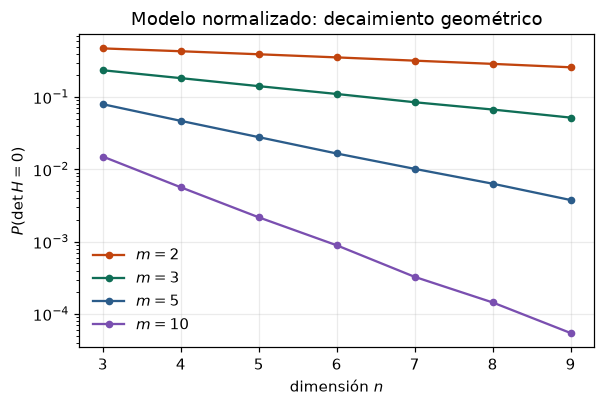

In [5]:
rng = np.random.default_rng(2025)
ns = list(range(3, 10))
Ksamp = {2: 300_000, 3: 400_000, 5: 800_000, 10: 1_500_000}
P = {m: [psing_normalized(n, m, Ksamp[m], rng=rng) for n in ns] for m in Ksamp}
# m = 20 es demasiado raro para contar directamente en n = 8; se usa el estimador de Rao-Blackwell de la Sección 4
P20 = {n: psing_rb_contribs(n, 20, K, rng=rng).mean() for n, K in [(5, 3_000_000), (8, 12_000_000)]}

print(f"{'n':>2} " + " ".join(f"{'m=' + str(m):>10}" for m in Ksamp) + f" {'m=20':>10}")
for i, n in enumerate(ns):
    p20 = f"{P20[n]:>10.2e}" if n in P20 else f"{'':>10}"
    print(f"{n:>2} " + " ".join(f"{P[m][i]:>10.3e}" for m in Ksamp) + " " + p20)
print("\nexacto (m=2): " + ", ".join(f"n={n}: {float(EXACT[(n, 2)]):.4f}" for n in (3, 4, 5, 6)))

fig, ax = plt.subplots(figsize=(5.6, 3.8))
for m in Ksamp:
    ax.semilogy(ns, P[m], "o-", color=COL[m], label=f"$m={m}$", lw=1.5, ms=4)
ax.set_xlabel("dimensión $n$")
ax.set_ylabel(r"$P(\det H=0)$")
ax.set_title("Modelo normalizado: decaimiento geométrico")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Estimación de $\gamma(m)$ por Rao-Blackwell

Para estimar la base $\gamma(m)$ con precisión, $h_{1,n}$ se integra analíticamente en lugar de muestrearse. Escribiendo $d_n=(-1)^{n-1}h_{1,n}+R$,

$$P(d_n=0\mid\text{resto})=\tfrac1m\,\mathbf 1\{(-1)^nR\in\{0,\dots,m-1\}\},$$

así que cada muestra aporta $0$ o $1/m$ en lugar de $0$ o $1$, lo que reduce la varianza en un factor de aproximadamente $m$. Luego se ajusta $\log P(n)=a+n\log\gamma+\alpha\log n$ (el término $\log n$ separa la base geométrica de un prefactor polinomial), con intervalos bootstrap al 95%. Como cada contribución es $0$ o $1/m$, los remuestreos bootstrap se generan como conteos binomiales, que tienen la misma distribución que remuestrear las contribuciones.

  m   gamma            95% CI  alpha  gamma*sqrt(m)
  2   0.894 [0.892, 0.896]   0.07          1.264
  3   0.793 [0.787, 0.799]  -0.12          1.373
  5   0.635 [0.619, 0.650]  -0.29          1.419
 10   0.430 [0.394, 0.471]  -0.48          1.361


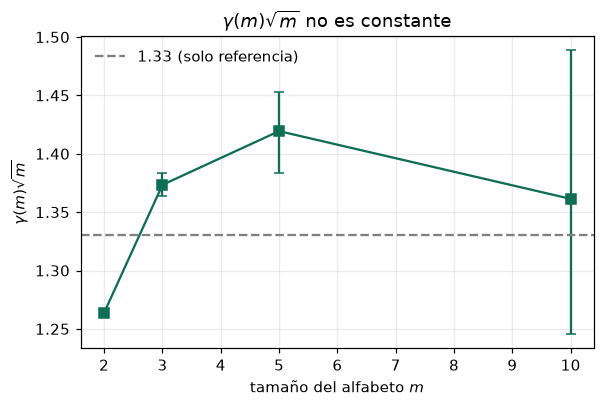

In [6]:
rng = np.random.default_rng(20260803)
plans = {2: (range(5, 15), 500_000), 3: (range(5, 13), 700_000),
         5: (range(5, 12), 1_000_000), 10: (range(4, 11), 1_500_000)}
G = {m: estimate_gamma(m, list(r), K, rng=rng) for m, (r, K) in plans.items()}

print(f"{'m':>3} {'gamma':>7} {'95% CI':>17} {'alpha':>6} {'gamma*sqrt(m)':>14}")
for m, g in G.items():
    print(f"{m:>3} {g['gamma']:>7.3f} [{g['ci'][0]:.3f}, {g['ci'][1]:.3f}] {g['alpha']:>6.2f}"
          f" {g['gamma'] * np.sqrt(m):>14.3f}")

ms = list(G)
gs = np.array([G[m]["gamma"] for m in ms])
lo = np.array([G[m]["ci"][0] for m in ms])
hi = np.array([G[m]["ci"][1] for m in ms])
fig, ax = plt.subplots(figsize=(5.6, 3.8))
sq = np.sqrt(ms)
ax.errorbar(ms, gs * sq, yerr=[(gs - lo) * sq, (hi - gs) * sq], fmt="s-", color="#0f6e56", capsize=3)
ax.axhline(1.33, ls="--", color="gray", label="1.33 (solo referencia)")
ax.set_xlabel("tamaño del alfabeto $m$")
ax.set_ylabel(r"$\gamma(m)\sqrt{m}$")
ax.set_title(r"$\gamma(m)\sqrt{m}$ no es constante")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

La base $\gamma(m)$ está muy por encima del $1/m$ del modelo denso (por ejemplo $\gamma(10)\approx 0.4$ contra $0.1$), así que la restricción Hessenberg hace la singularidad mucho más común. Sin embargo, $\gamma(m)\sqrt m$ no es constante en el rango probado, por lo que una ley limpia $m^{-1/2}$ no tiene soporte. Esto es una afirmación solo sobre alfabetos pequeños: en $m=20$ la probabilidad ya es $\sim10^{-4}$ en $n=5$, así que $\gamma$ no se puede fijar ahí con muestreo exacto, y los alfabetos pequeños son justamente donde los efectos de divisibilidad entre los menores son más fuertes.

## 5. Mecanismo: exponente de Lyapunov y resonancia aritmética

Del Teorema 3, $P(d_n=0)=\tfrac1m\,\mathbb E\left[P(R\in\{0,\dots,m-1\})\right]$, donde $R$ es un entero cuya escala la fija $|d_{n-1}|$. Los menores crecen exponencialmente con el exponente de Lyapunov

$$\lambda(m)=\lim_{k\to\infty}\frac1k\log|d_k|$$

(entendido como tasa de crecimiento casi segura, ya que $d_k=0$ tiene probabilidad positiva). Caer en una ventana fija dentro de un rango exponencialmente grande sugiere la descomposición

$$\gamma(m)=e^{-\lambda(m)}\rho(m),\qquad \rho(m)\geq1,$$

con $\rho$ un factor de resonancia aritmética. $\lambda(m)$ se estima en dimensiones hasta $n=1000$ (factible gracias a la recurrencia $O(n^2)$) reescalando el vector de menores en cada paso y generando una columna por paso. La estimación se reporta en $n=250, 500, 1000$ para mostrar que es estable.

  m  lambda(250)  lambda(500)  lambda(1000)     s.e.  e^-lambda   gamma    rho      rho 95% CI
  2       0.1112       0.1136        0.1148  9.7e-05      0.892   0.894   1.00 [1.00, 1.00]
  3       0.2667       0.2684        0.2688  1.8e-04      0.764   0.793   1.04 [1.03, 1.04]
  5       0.5839       0.5852        0.5844  3.4e-04      0.557   0.635   1.14 [1.11, 1.17]
 10       1.1740       1.1744        1.1748  5.1e-04      0.309   0.430   1.39 [1.28, 1.52]


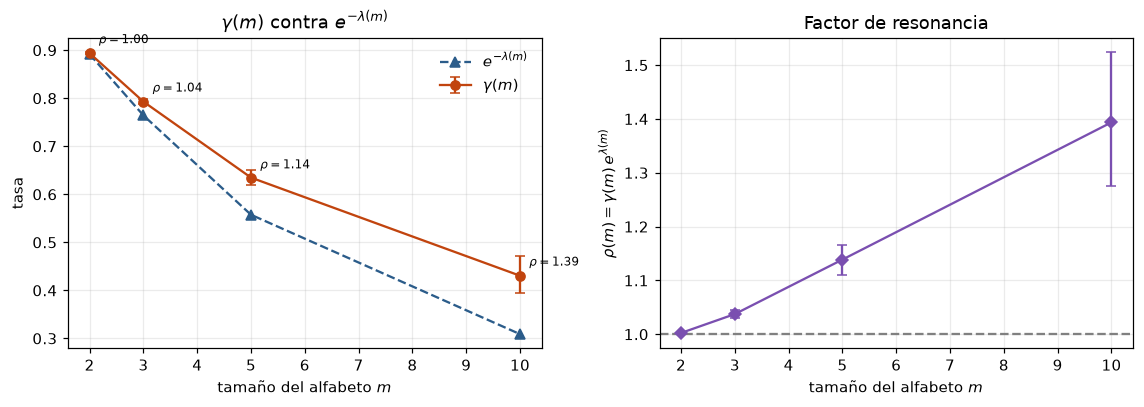

In [7]:
rng = np.random.default_rng(7)
LAM = {m: lyapunov(m, n=1000, K=4000 if FULL else 2000, rng=rng) for m in ms}

print(f"{'m':>3} {'lambda(250)':>12} {'lambda(500)':>12} {'lambda(1000)':>13} {'s.e.':>8}"
      f" {'e^-lambda':>10} {'gamma':>7} {'rho':>6} {'rho 95% CI':>15}")
RHO = {}
for m in ms:
    lam, se = LAM[m][1000]
    e = np.exp(lam)
    RHO[m] = (G[m]["gamma"] * e, G[m]["ci"][0] * e, G[m]["ci"][1] * e)
    print(f"{m:>3} {LAM[m][250][0]:>12.4f} {LAM[m][500][0]:>12.4f} {lam:>13.4f} {se:>8.1e}"
          f" {1 / e:>10.3f} {G[m]['gamma']:>7.3f} {RHO[m][0]:>6.2f} [{RHO[m][1]:.2f}, {RHO[m][2]:.2f}]")

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax = axs[0]
ax.errorbar(ms, gs, yerr=[gs - lo, hi - gs], fmt="o-", color="#c1440e", capsize=3, label=r"$\gamma(m)$")
ax.plot(ms, [np.exp(-LAM[m][1000][0]) for m in ms], "^--", color="#2b5c8a", label=r"$e^{-\lambda(m)}$")
for m in ms:
    ax.annotate(rf"$\rho={RHO[m][0]:.2f}$", (m, G[m]["gamma"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("tamaño del alfabeto $m$")
ax.set_ylabel("tasa")
ax.set_title(r"$\gamma(m)$ contra $e^{-\lambda(m)}$")
ax.legend(frameon=False)
ax = axs[1]
r = np.array([RHO[m] for m in ms])
ax.errorbar(ms, r[:, 0], yerr=[r[:, 0] - r[:, 1], r[:, 2] - r[:, 0]], fmt="D-", color="#7a4fb0", capsize=3)
ax.axhline(1, ls="--", color="gray")
ax.set_xlabel("tamaño del alfabeto $m$")
ax.set_ylabel(r"$\rho(m)=\gamma(m)\,e^{\lambda(m)}$")
ax.set_title("Factor de resonancia")
plt.tight_layout()
plt.show()

$\lambda(m)$ es estable desde $n\approx250$, con errores estándar de alrededor de $10^{-3}$, dos órdenes de magnitud por debajo de la incertidumbre de $\gamma$, así que el intervalo de $\rho$ se propaga solo desde $\gamma$. La suposición ingenua $\rho=1$ ($\gamma=e^{-\lambda}$) se cumple en $m=2$ pero $\rho$ crece con $m$: la singularidad es más probable de lo que predice el crecimiento por sí solo, porque los menores comparten estructura aritmética que concentra $R$ en una subred y agranda su átomo en 0.

**Conjetura 1.** Para cada $m\geq2$ el límite $\gamma(m)=\lim_n P(d_n=0)^{1/n}$ existe y $\gamma(m)=e^{-\lambda(m)}\rho(m)$, con $\rho(m)\geq1$. Esto no es un corolario de la teoría estándar: la existencia de tasas exponenciales para productos aleatorios usualmente viene de Furstenberg-Kesten, Oseledets o Kingman, que requieren mapas estacionarios sobre un espacio fijo. Aquí $D_k=(d_k,\dots,d_0)$ tiene dimensión $k+1$, que crece en cada paso, así que ninguno aplica directamente.

## 6. El modelo libre: la estructura regresa

Con una subdiagonal aleatoria, un solo $s_i=0$ hace que $H$ sea triangular por bloques, y $H$ es singular siempre que alguno de los bloques lo sea. Como $P(\exists\, s_i=0)\approx(n-1)/m$, la singularidad se vuelve estructural y crece con $n$, y el corango puede ser mayor que 1. A continuación: la probabilidad de singularidad de ambos modelos, la fracción de matrices libres singulares que tienen una entrada nula en la subdiagonal, y el corango exacto de una muestra de matrices libres singulares.

 m  n  P libre P normalizado  s_i nulo | singular  conteo de corango
 3  3   0.4162        0.2348                0.748  {1: 279, 2: 21}
 3  4   0.4566        0.1827                0.882  {1: 272, 2: 28}
 3  5   0.4924        0.1415                0.946  {1: 281, 2: 19}
 3  6   0.5321        0.1104                0.973  {1: 279, 2: 21}
 3  7   0.5661        0.0848                0.988  {1: 273, 2: 27}
 3  8   0.5978        0.0672                0.994  {1: 270, 2: 29, 3: 1}
 3  9   0.6309        0.0520                0.997  {1: 267, 2: 33}
 5  3   0.1690        0.0796                0.699  {1: 294, 2: 6}
 5  4   0.1708        0.0469                0.863  {1: 294, 2: 6}
 5  5   0.1775        0.0279                0.942  {1: 300}
 5  6   0.1889        0.0166                0.975  {1: 298, 2: 2}
 5  7   0.1989        0.0102                0.989  {1: 295, 2: 5}
 5  8   0.2139        0.0063                0.996  {1: 297, 2: 3}
 5  9   0.2232        0.0038                0.998  {1: 296, 2: 4}


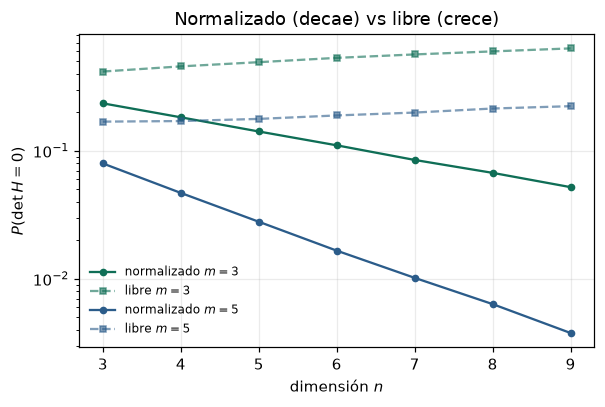

In [8]:
rng = np.random.default_rng(11)
PF, ZERO, CORANK = {}, {}, {}
for m in (3, 5):
    PF[m], ZERO[m], CORANK[m] = [], [], []
    for n in ns:
        p, frac, mats = psing_free(n, m, 150_000, rng=rng, return_samples=300)
        PF[m].append(p)
        ZERO[m].append(frac)
        CORANK[m].append(Counter(n - exact_rank(M) for M in mats))

print(f"{'m':>2} {'n':>2} {'P libre':>8} {'P normalizado':>13} {'s_i nulo | singular':>20}  conteo de corango")
for m in (3, 5):
    for i, n in enumerate(ns):
        print(f"{m:>2} {n:>2} {PF[m][i]:>8.4f} {P[m][i]:>13.4f} {ZERO[m][i]:>20.3f}  {dict(sorted(CORANK[m][i].items()))}")

fig, ax = plt.subplots(figsize=(5.6, 3.8))
for m in (3, 5):
    ax.semilogy(ns, P[m], "o-", color=COL[m], lw=1.5, ms=4, label=f"normalizado $m={m}$")
    ax.semilogy(ns, PF[m], "s--", color=COL[m], lw=1.5, ms=4, alpha=0.6, label=f"libre $m={m}$")
ax.set_xlabel("dimensión $n$")
ax.set_ylabel(r"$P(\det H=0)$")
ax.set_title("Normalizado (decae) vs libre (crece)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Los dos modelos son la fase estructural y la fase genuina del mismo objeto, separadas por una sola decisión de modelado. Reducir la banda al caso tridiagonal tampoco conserva el fenómeno: la última columna tiene solo dos entradas libres y se anula con probabilidad $1/m^2$. Lo que importa es el triángulo superior denso.

## 7. Número de condición

El mecanismo de singularidad controla el borde inferior del espectro de valores singulares y por lo tanto el número de condición $\kappa=\sigma_{\max}/\sigma_{\min}$. Los valores singulares se calculan por SVD en lotes de matrices normalizadas con $n=6$. Las matrices exactamente singulares se marcan con la recurrencia entera y se quitan antes de la SVD, para que el átomo en $\kappa=\infty$ no se filtre al resto de la distribución por ruido de punto flotante.

Este es el condicionamiento del miembro de máxima aleatoriedad de la clase de forma Hessenberg superior. Es una línea base, no un modelo de las matrices Hessenberg producidas por Arnoldi o GMRES, cuyas entradas están correlacionadas y heredan el espectro del operador.

La separación importa para $m=2$, donde cerca de un tercio de las matrices son exactamente singulares: si se mantienen (su $\sigma_{\min}$ en punto flotante es muy pequeño pero no cero), la mediana de $\kappa$ pasa de aproximadamente 10 a aproximadamente 13, el valor reportado en el escrito. Para $m=5$ y $m=10$ la diferencia es despreciable.

  m mediana kappa               RIC   exact. singular


  2          10.1 [   7.8,    13.0]            0.3536


  3          25.1 [  16.4,    42.0]            0.1092


  5          58.8 [  32.8,   124.4]            0.0175


 10         117.4 [  53.3,   313.5]            0.0009


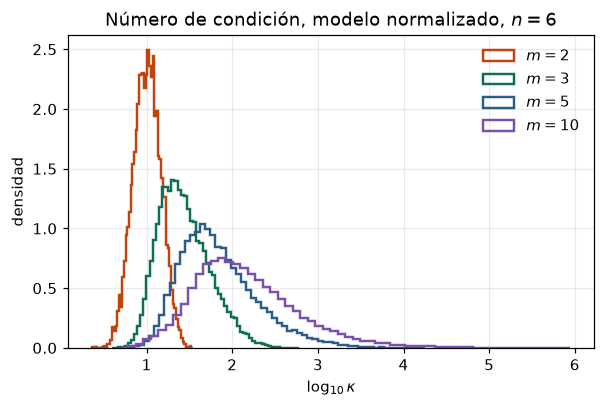

In [9]:
rng = np.random.default_rng(13)
fig, ax = plt.subplots(figsize=(5.6, 3.8))
print(f"{'m':>3} {'mediana kappa':>13} {'RIC':>17} {'exact. singular':>17}")
for m in (2, 3, 5, 10):
    ks, n_sing = condition_numbers(6, m, 40_000, normalized=True, rng=rng)
    q1, q2, q3 = np.percentile(ks, [25, 50, 75])
    print(f"{m:>3} {q2:>13.1f} [{q1:>6.1f}, {q3:>7.1f}] {n_sing / 40_000:>17.4f}")
    ax.hist(np.log10(ks), bins=60, histtype="step", lw=1.6, color=COL[m], label=f"$m={m}$", density=True)
ax.set_xlabel(r"$\log_{10}\kappa$")
ax.set_ylabel("densidad")
ax.set_title(r"Número de condición, modelo normalizado, $n=6$")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Densidad de valores propios

No es parte del análisis de singularidad, pero sitúa a la familia dentro de la tradición Bohemia: la densidad empírica de valores propios de la familia normalizada para $n=5$, alfabeto $\{0,1,2,3\}$ ($m=4$). Los valores propios se acumulan en un histograma 2D fijo, así que nunca es necesario guardar las $10^8$ muestras a la vez. Los valores propios se agrupan cerca del eje real, con vacíos circulares alrededor de los enteros pequeños.

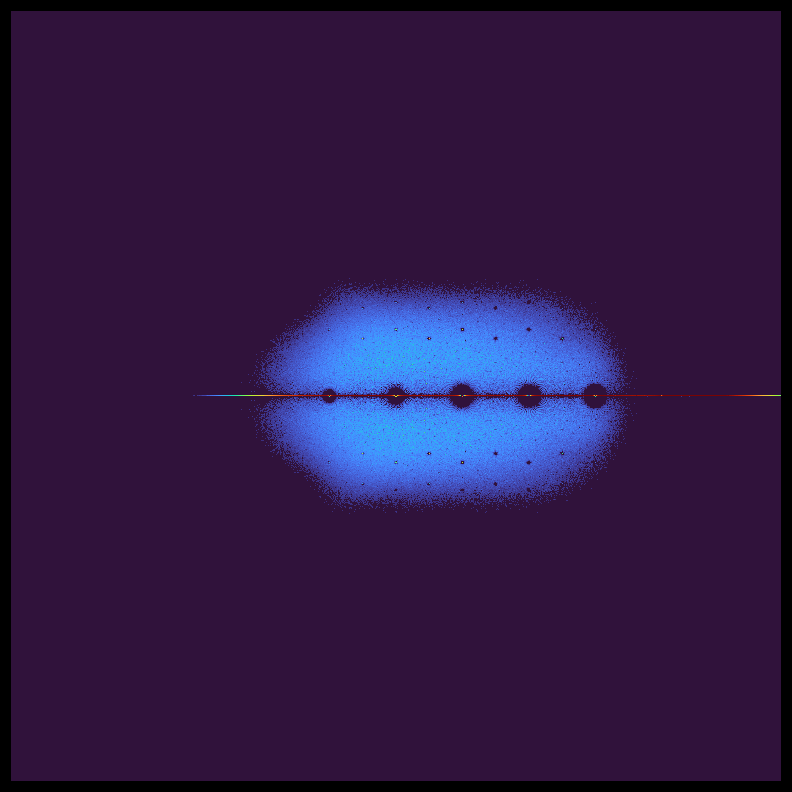

10,000,000 matrices, extensión = 5.79, tiempo total del cuaderno: 8.8 min


In [10]:
N_EIG = 100_000_000 if FULL else 10_000_000
Hist, ext = bohemian_density(5, [0, 1, 2, 3], num_samples=N_EIG, bins=1400, structure="hessenberg", seed=4)
fig = render(Hist, ext, None, cmap="turbo", gamma=0.3, size=7)
plt.show()
print(f"{N_EIG:,} matrices, extensión = {ext:.2f}, tiempo total del cuaderno: {(time.time() - T0) / 60:.1f} min")

## Resumen

* Modelo normalizado: corango $\leq1$ siempre, la singularidad estructural es $O(m^{-n})$, y $P(\text{singular})\leq1/m$, alcanzada en $n=m=2$. Una matriz normalizada singular es singular por una razón aritmética genuina, a diferencia del caso denso i.i.d.
* $P(\text{singular})=\Theta(\gamma(m)^n)$ con $\gamma(m)$ muy por encima de $1/m$; $\gamma(m)\sqrt m$ no es constante para $m\leq10$.
* $\gamma(m)=e^{-\lambda(m)}\rho(m)$ separa el crecimiento de los menores de un factor de resonancia aritmética que va de $\rho\approx1$ en $m=2$ hacia arriba. La existencia de $\gamma(m)$ es una conjetura, porque el vector de estado de la recurrencia crece en dimensión en cada paso.
* El modelo libre regresa a la singularidad estructural, así que es el triángulo superior denso, y no solo la forma Hessenberg, lo que produce el fenómeno.
* El número de condición crece con $m$; se ofrece como una línea base de modelo nulo para reducciones de Krylov y de sistemas abiertos, no como un modelo de ellas.